In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:
df = pd.read_csv('prediction_traffic(new).csv')
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,date_time,hour,day_of_week,month,weather_main_Clouds,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
0,5545,0,0.530370,-0.007463,-0.027228,2012-10-02 09:00:00,9,1,10,1,...,0,0,0,0,0,0,0,7.071068e-01,-0.707107,0
1,4516,0,0.611341,-0.007463,-0.027228,2012-10-02 10:00:00,10,1,10,1,...,0,0,0,0,0,0,0,5.000000e-01,-0.866025,0
2,4767,0,0.627836,-0.007463,-0.027228,2012-10-02 11:00:00,11,1,10,1,...,0,0,0,0,0,0,0,2.588190e-01,-0.965926,0
3,5026,0,0.669071,-0.007463,-0.027228,2012-10-02 12:00:00,12,1,10,1,...,0,0,0,0,0,0,0,1.224647e-16,-1.000000,0
4,4918,0,0.744794,-0.007463,-0.027228,2012-10-02 13:00:00,13,1,10,1,...,0,0,0,0,0,0,0,-2.588190e-01,-0.965926,0


In [ ]:
df.set_index('date_time', inplace=True)
df.sort_index(inplace=True)

In [ ]:
correlation = df.corr()['traffic_volume'].abs().sort_values(ascending=False)
print(correlation)

selected_features_corr = correlation[correlation > 0.05].index.tolist()

print("\n=== Features with |correlation| > 0.05 ===")
print(selected_features_corr)

traffic_volume               1.000000
hour_cos                     0.764252
hour                         0.352401
hour_sin                     0.244211
is_weekend                   0.218647
day_of_week                  0.149544
temp                         0.130299
weather_main_Clouds          0.122285
weather_main_Mist            0.061734
holiday                      0.042897
weather_main_Fog             0.038868
weather_main_Snow            0.030804
weather_main_Haze            0.020778
weather_main_Thunderstorm    0.019241
weather_main_Rain            0.010676
weather_main_Squall          0.005493
rain_1h                      0.004714
weather_main_Drizzle         0.003082
month                        0.002533
snow_1h                      0.000733
weather_main_Smoke           0.000227
Name: traffic_volume, dtype: float64

=== Features with |correlation| > 0.05 ===
['traffic_volume', 'hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'temp', 'weather_main_Clouds', 'weather_m

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#define features and target
selected_features_corr.remove('traffic_volume')

X = df[selected_features_corr]
y = df['traffic_volume']

print("Selected features for Linear Regression:", X.columns.tolist())


Selected features for Linear Regression: ['hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'temp', 'weather_main_Clouds', 'weather_main_Mist']


In [ ]:
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,hour,day_of_week,month,weather_main_Clouds,weather_main_Drizzle,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
date_time,,,,,,,,,,,,,,,,,,,,,
2012-10-02 09:00:00,5545,0,0.530370,-0.007463,-0.027228,9,1,10,1,0,...,0,0,0,0,0,0,0,7.071068e-01,-0.707107,0
2012-10-02 10:00:00,4516,0,0.611341,-0.007463,-0.027228,10,1,10,1,0,...,0,0,0,0,0,0,0,5.000000e-01,-0.866025,0
2012-10-02 11:00:00,4767,0,0.627836,-0.007463,-0.027228,11,1,10,1,0,...,0,0,0,0,0,0,0,2.588190e-01,-0.965926,0
2012-10-02 12:00:00,5026,0,0.669071,-0.007463,-0.027228,12,1,10,1,0,...,0,0,0,0,0,0,0,1.224647e-16,-1.000000,0
2012-10-02 13:00:00,4918,0,0.744794,-0.007463,-0.027228,13,1,10,1,0,...,0,0,0,0,0,0,0,-2.588190e-01,-0.965926,0


In [ ]:
split_date = '2018-01-01'

train = df[df.index < split_date]
test = df[df.index >= split_date]

# 3. Define X and y for both sets
X_train = train[selected_features_corr]
y_train = train['traffic_volume']

X_test = test[selected_features_corr]
y_test = test['traffic_volume']

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Create polynomial features (degree = 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)


In [ ]:
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
# Transform features into polynomial form
y_train_poly_pred = poly_model.predict(X_train_poly)
y_test_poly_pred = poly_model.predict(X_test_poly)

In [ ]:
# Add poly prediction as a new feature
X_train_stack = X_train.copy()
X_train_stack['poly_pred'] = y_train_poly_pred

X_test_stack = X_test.copy()
X_test_stack['poly_pred'] = y_test_poly_pred

In [ ]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train_stack, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [ ]:
# Final predictions
y_pred_hybrid = rf_model.predict(X_test_stack)

In [ ]:
# Evaluation
mae = mean_absolute_error(y_test, y_pred_hybrid)
mse = mean_squared_error(y_test, y_pred_hybrid)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_hybrid)
mape = np.mean(np.abs((y_test - y_pred_hybrid)/y_test)) * 100

print("=== Polynomial Regression + Random Forest (Hybrid Stacking) ===")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("MAPE:", mape)

=== Polynomial Regression + Random Forest (Hybrid Stacking) ===
MAE: 324.7934149789839
RMSE: 559.5206983878045
R2 Score: 0.9195747797469753
MAPE: 14.531116049019074


Random Forest corrects errors of polynomial regression, improving predictions.

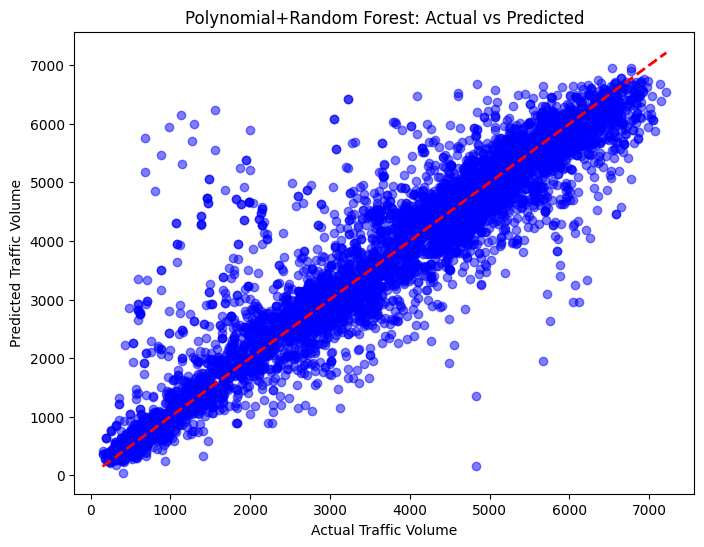

In [ ]:
import matplotlib.pyplot as plt

# Plot 1: Scatter plot
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_hybrid, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")
plt.title("Polynomial+Random Forest: Actual vs Predicted")
plt.show()

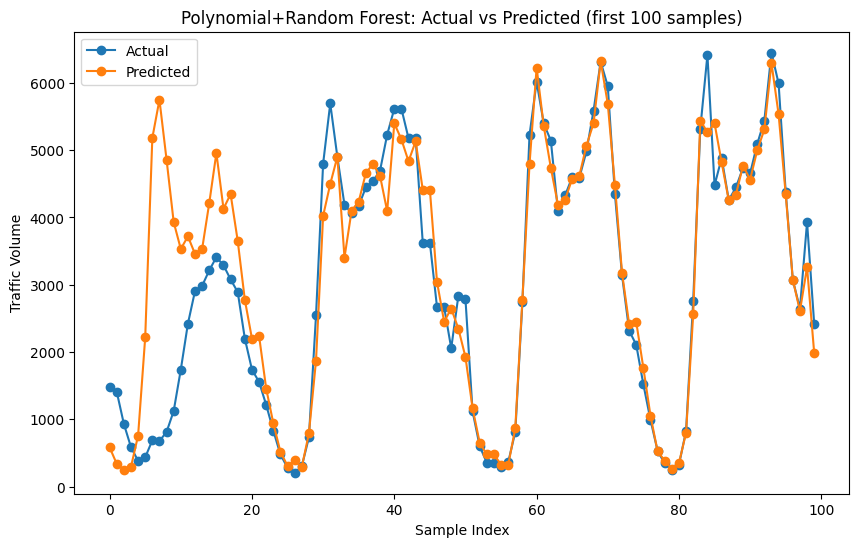

In [ ]:
import matplotlib.pyplot as plt

# Plot 2: first 100 samples
plt.figure(figsize=(10,6))
plt.plot(range(100), y_test.iloc[:100], label='Actual', marker='o')
plt.plot(range(100), y_pred_hybrid[:100], label='Predicted', marker='o')
plt.xlabel('Sample Index')
plt.ylabel('Traffic Volume')
plt.title("Polynomial+Random Forest: Actual vs Predicted (first 100 samples)")
plt.legend()
plt.show()


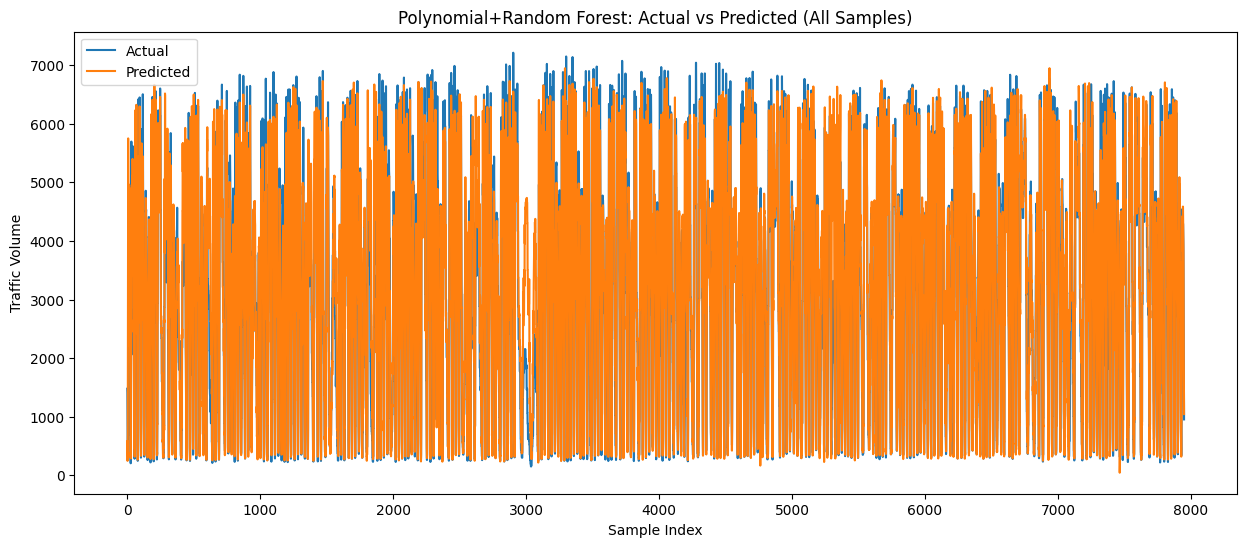

In [ ]:
import matplotlib.pyplot as plt

# Plot 3: all samples
plt.figure(figsize=(15,6))
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred_hybrid, label='Predicted')
plt.xlabel('Sample Index')
plt.ylabel('Traffic Volume')
plt.title('Polynomial+Random Forest: Actual vs Predicted (All Samples)')
plt.legend()
plt.show()

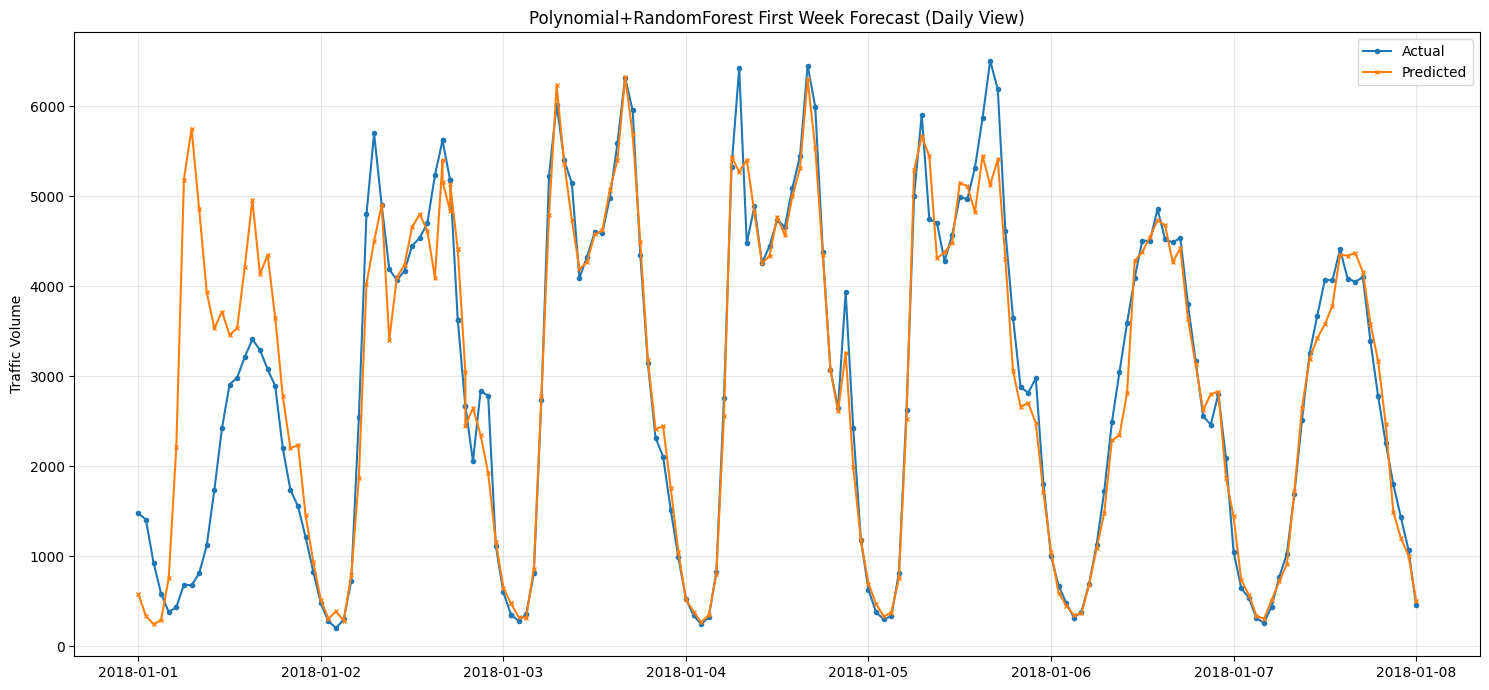

In [ ]:
import matplotlib.dates as mdates

# Plot 4: First week forecast

y_test.index = pd.to_datetime(y_test.index)

test_start = y_test.index[0]
test_first_week = test_start + pd.Timedelta(days=7)
mask = (y_test.index >= test_start) & (y_test.index <= test_first_week)

plt.figure(figsize=(15,7))

plt.plot(y_test.index[mask], y_test[mask], label='Actual', marker='o', markersize=3)
plt.plot(y_test.index[mask], y_pred_hybrid[mask], label='Predicted', marker='x', markersize=3)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))

plt.title('Polynomial+RandomForest First Week Forecast (Daily View)')
plt.ylabel('Traffic Volume')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

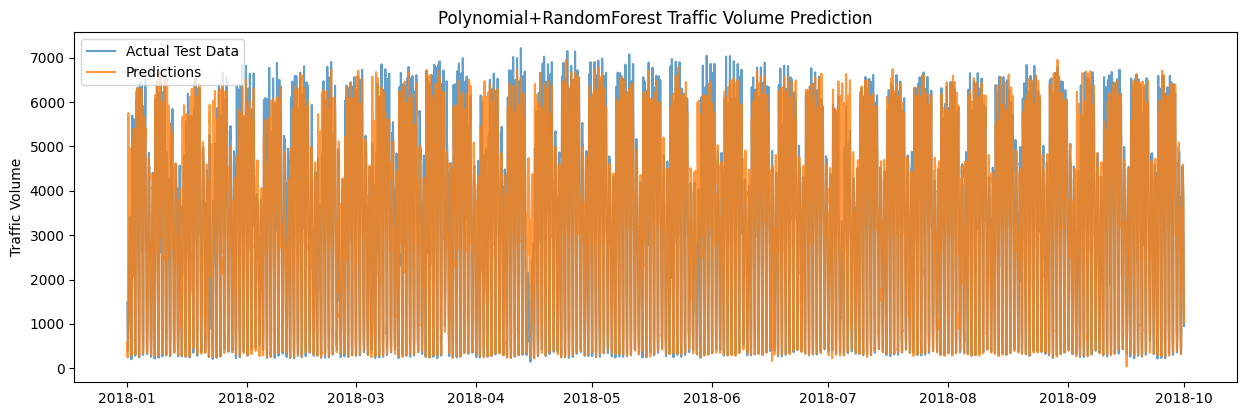

In [ ]:
plt.figure(figsize=(15, 10))

# Plot 5: Full series with predictions
plt.subplot(2, 1, 1)
plt.plot(y_test.index, y_test, label='Actual Test Data', alpha=0.7)
plt.plot(y_test.index, y_pred_hybrid, label='Predictions', alpha=0.8)

plt.title('Polynomial+RandomForest Traffic Volume Prediction')
plt.ylabel('Traffic Volume')
plt.legend()

Residuals

In [ ]:
residuals = y_test - y_pred_hybrid

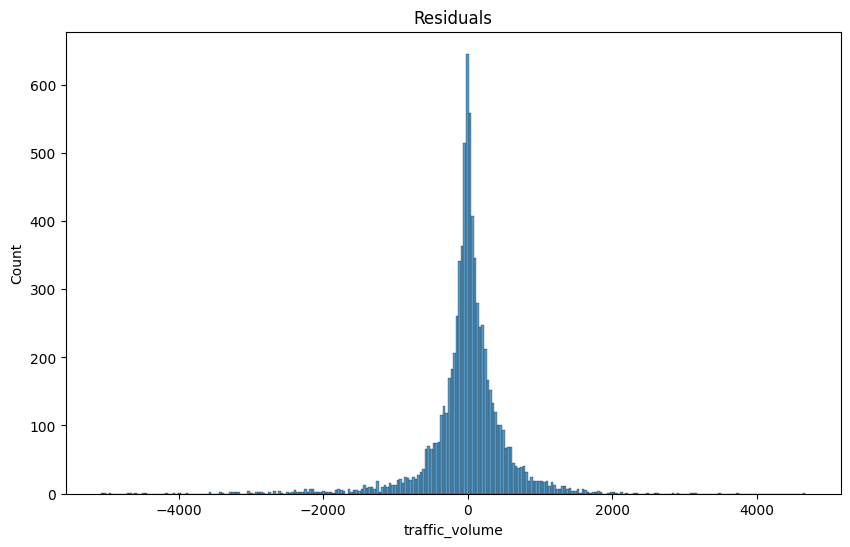

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#plot residuals
plt.figure(figsize=(10,6))
sns.histplot(residuals)
plt.title('Residuals')
plt.show()

Forecast (1 year)

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Create future dates for 1 year
future_dates = pd.date_range(start=pd.to_datetime('2018-10-01') + timedelta(hours=1),
                            periods=365*24, freq='h')

def create_future_features(future_dates, df):
    future_df = pd.DataFrame({'date_time': future_dates})

    # Extract basic time features
    future_df['hour'] = future_df['date_time'].dt.hour
    future_df['day_of_week'] = future_df['date_time'].dt.dayofweek

    # Create the same engineered features that used in training
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour']/24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour']/24)
    future_df['is_weekend'] = future_df['day_of_week'].isin([5, 6]).astype(int)

    # Use average temp and default weather
    future_df['temp'] = df['temp'].mean()
    future_df['weather_main_Clouds'] = 1
    future_df['weather_main_Clear'] = 1
    future_df['weather_main_Mist'] = 1

    future_df = future_df.set_index('date_time')
    future_X = future_df[X.columns] # keep only the features used for prediction

    return future_df, future_X

# Create future features
future_df, future_X = create_future_features(future_dates, df)

In [ ]:
# Transform features to polynomial features
future_X_poly = poly.transform(future_X)
poly_pred_future = poly_model.predict(future_X_poly)

# Add polynomial prediction as a new feature for rf
future_X_stack = future_X.copy()
future_X_stack['poly_pred'] = poly_pred_future

future_df['predicted_traffic'] = rf_model.predict(future_X_stack)

# Confidence interval (±10%)
future_df['lower_ci'] = future_df['predicted_traffic'] * 0.9
future_df['upper_ci'] = future_df['predicted_traffic'] * 1.1

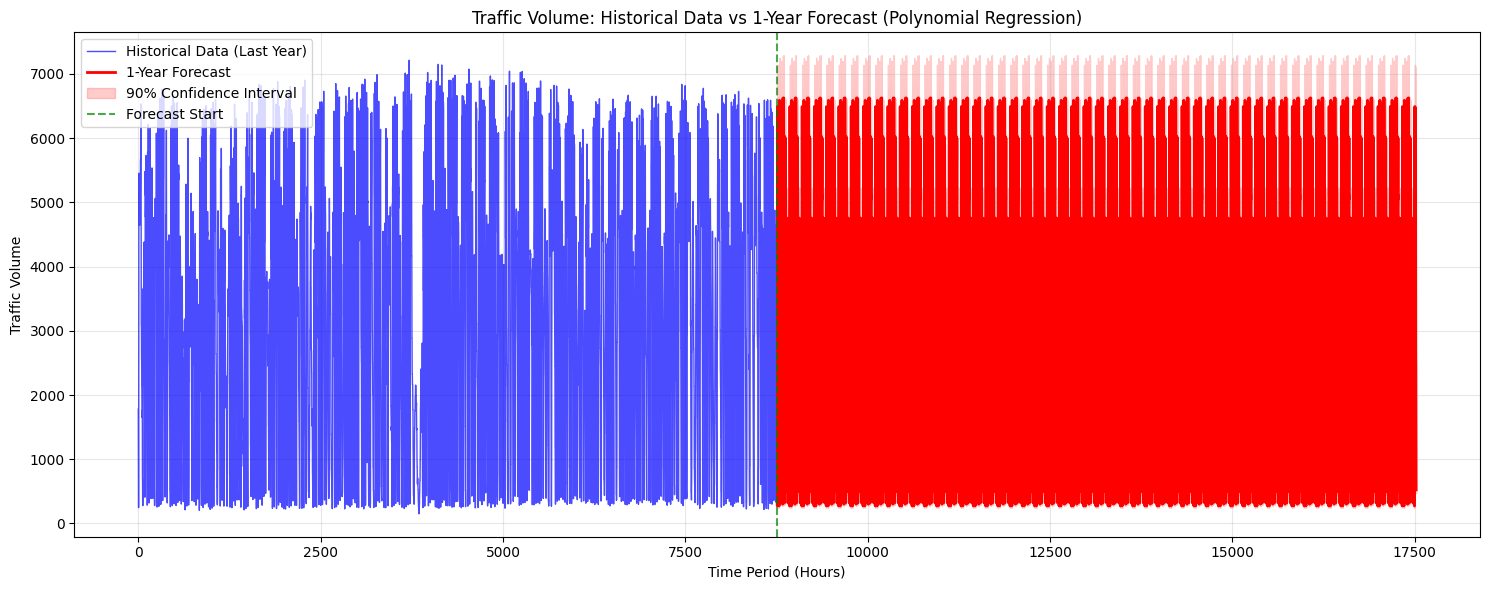

In [ ]:
plt.figure(figsize=(15,6))

# Historical data (last year)
historical_data = df['traffic_volume'].iloc[-365*24:]
historical_indices = range(len(historical_data))
plt.plot(historical_indices, historical_data,
         label='Historical Data (Last Year)', color='blue', alpha=0.7, linewidth=1)

# Forecast
forecast_indices = range(len(historical_data), len(historical_data) + len(future_df))
plt.plot(forecast_indices, future_df['predicted_traffic'],
         label='1-Year Forecast', color='red', linewidth=2)

# Confidence interval
plt.fill_between(forecast_indices,
                 future_df['lower_ci'],
                 future_df['upper_ci'],
                 color='red', alpha=0.2, label='90% Confidence Interval')

# Vertical line for forecast start
plt.axvline(x=len(historical_data), color='green', linestyle='--',
            alpha=0.7, label='Forecast Start')

plt.title('Traffic Volume: Historical Data vs 1-Year Forecast (Polynomial Regression)')
plt.xlabel('Time Period (Hours)')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Forecast (1 week)

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Create future dates for 1 week
future_dates = pd.date_range(start=pd.to_datetime('2018-10-01') + timedelta(hours=1),
                            periods=7*24, freq='h')

def create_future_features(future_dates, df):
    future_df = pd.DataFrame({'date_time': future_dates})

    # Extract basic time features
    future_df['hour'] = future_df['date_time'].dt.hour
    future_df['day_of_week'] = future_df['date_time'].dt.dayofweek

    # Create the same engineered features you used in training
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour']/24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour']/24)
    future_df['is_weekend'] = future_df['day_of_week'].isin([5, 6]).astype(int)

    future_df['temp'] = df['temp'].mean()
    future_df['weather_main_Clouds'] = 1
    future_df['weather_main_Clear'] = 1
    future_df['weather_main_Mist'] = 1

    future_df = future_df.set_index('date_time')
    future_X = future_df[X.columns]

    return future_df, future_X

# Create future features
future_df, future_X = create_future_features(future_dates, df)

In [ ]:
future_X_poly = poly.transform(future_X)

# Polynomial prediction
poly_pred_future = poly_model.predict(future_X_poly)

# Random Forest prediction using poly_pred as feature
future_X_stack = future_X.copy()
future_X_stack['poly_pred'] = poly_pred_future

# Final hybrid forecast
future_df['predicted_traffic'] = rf_model.predict(future_X_stack)

In [ ]:
#Confidence Interval

future_df['lower_ci'] = future_df['predicted_traffic'] * 0.9
future_df['upper_ci'] = future_df['predicted_traffic'] * 1.1


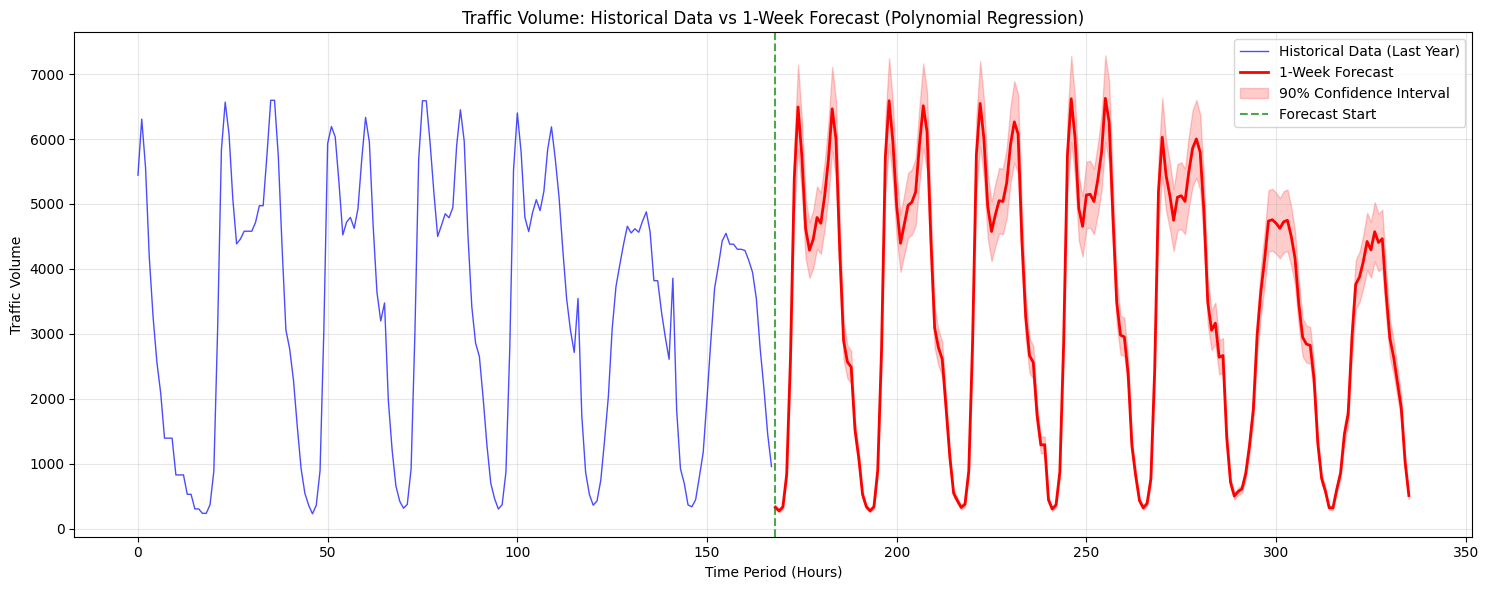

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

# Historical data (last week)
historical_data = df['traffic_volume'].iloc[-7*24:]
historical_indices = range(len(historical_data))
plt.plot(historical_indices, historical_data,
         label='Historical Data (Last Year)', color='blue', alpha=0.7, linewidth=1)

# Forecast
forecast_indices = range(len(historical_data), len(historical_data) + len(future_df))
plt.plot(forecast_indices, future_df['predicted_traffic'],
         label='1-Week Forecast', color='red', linewidth=2)

# Confidence interval
plt.fill_between(forecast_indices,
                 future_df['lower_ci'],
                 future_df['upper_ci'],
                 color='red', alpha=0.2, label='90% Confidence Interval')

# Vertical line for forecast start
plt.axvline(x=len(historical_data), color='green', linestyle='--',
            alpha=0.7, label='Forecast Start')

plt.title('Traffic Volume: Historical Data vs 1-Week Forecast (Polynomial Regression)')
plt.xlabel('Time Period (Hours)')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
